# Notebook 05: Learning when to stop (Q-learning)

**Project:** Hacker Statistics, chances of winning a bet  
So far the climber had no choices: roll 100 times and see where you land. This notebook gives the climber one decision after every roll, **roll again or stop**, and asks what the best rule is. We find it two ways and compare:

1. **Exact:** work backwards from the last roll (dynamic programming, the same idea as the value map in notebook 02).
2. **Learned:** a program that knows *nothing* about the dice probabilities plays 400,000 games and works out a rule by trial and error. This is **Q-learning**, a basic form of reinforcement learning.

Because we have the exact answer, we can measure how good the learned rule really is.

**How each section is laid out:** what we are looking for, the code, its result, how to read it, what it means, and what's next and why.

## 1. Setup

### What we are looking for
Imports and the functions for this notebook, which live in `src/stopping.py` (tested in `tests/test_stopping.py`).

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.hacker_stats import exact_win_chance
from src.stopping import optimal_stopping, evaluate_policy, occupancy, q_learn, greedy_roll_mask

RED, BLUE, GREY, GOLD = "#9A3B2E", "#2F6690", "#a39b93", "#A87613"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

ROLLS, TARGET, CLUMSY, FEE = 100, 60, 0.001, 0.005
print("Setup complete.")

Setup complete.


### How to read it
Nothing to interpret yet; the line confirms the imports worked.

### What it means
Everything below uses the same game as before (100 rolls, target step 60, 0.1% clumsiness) plus one new setting, the fee per roll.

### What's next and why
Next we define the new game precisely, because a "best rule" only makes sense once the payoffs are written down.

## 2. The stopping game and three simple rules

### What we are looking for
A game where stopping is a real decision. The rules:

- After any roll you may **stop**. If you stop on step 60 or higher you **collect a prize of 1**. If you stop below 60 you walk away with nothing (we call that *quitting*).
- **Every roll costs a fee of 0.005**, half a percent of the prize. The game also ends by itself after 100 rolls.
- Your payoff is the prize (if you collect it) minus all the fees you paid.

This creates a real trade-off. Stopping the moment you reach 60 locks in the prize and saves fees, because a later clumsy fall could take it away. But quitting when you are far behind saves fees that would otherwise be wasted. When should you do which?

First we score three simple rules, so the clever answer has something to beat. Every score is an exact expected payoff, with no simulation noise.

In [2]:
size = 6 * ROLLS + 8
steps = np.arange(size)

never_play = np.zeros((ROLLS, size), dtype=bool)                  # stop at once: payoff 0
play_to_end = np.ones((ROLLS, size), dtype=bool)                  # roll all 100 times, no stopping
bank_at_target = np.tile(steps < TARGET, (ROLLS, 1))              # roll until you reach 60, then stop

rules = {
    "Stop at once (never play)": never_play,
    "Play all 100 rolls": play_to_end,
    "Roll until you reach step 60, then stop": bank_at_target,
}
print(f"{'Rule':<44}{'Expected payoff':>16}")
for name, mask in rules.items():
    print(f"{name:<44}{evaluate_policy(mask, ROLLS, TARGET, CLUMSY, FEE):>16.3f}")
print()
print(f"For reference, the original game (no fee, no stopping): chance of winning = {exact_win_chance(ROLLS, TARGET, CLUMSY):.1%}")

Rule                                         Expected payoff
Stop at once (never play)                              0.000
Play all 100 rolls                                     0.277
Roll until you reach step 60, then stop                0.414

For reference, the original game (no fee, no stopping): chance of winning = 77.7%


### How to read it
Each row is a fixed rule and its exact expected payoff, in units of the prize. A payoff of 0.4 means that on average you come out 40% of a prize ahead after paying all fees.

### What it means
"Play all 100 rolls" pays only about 0.28: the original game's 77.7% chance of winning, minus 100 fees of 0.005 (half a prize). Stopping at once pays exactly 0. Rolling until you reach 60 and then stopping does best of the three at about 0.41, because it collects the prize early, avoids the risk of falling afterward and stops paying fees.

Notice what none of the simple rules do: **quit when it is hopeless.** A climber on step 5 with 10 rolls left will almost certainly lose and keeps paying 0.005 per roll for nothing.

### What's next and why
Is there a better rule than "roll until 60"? We compute the exact best one by working backwards from the final roll.

## 3. The exact best rule (dynamic programming)

### What we are looking for
For every position (roll number, step) the best action, and the best expected payoff. We start at roll 100 where the game ends by itself, and work backwards. At each position we compare two numbers: the payoff of stopping now (1 if the step is 60+, else 0) and the payoff of rolling once more, which is minus the fee plus the average of the best values of the positions we might reach. The higher one is the best action. This is the same backwards recursion as the value map in notebook 02, with a choice added at every step.

In [3]:
W, cont, stop = optimal_stopping(ROLLS, TARGET, CLUMSY, FEE)
best_roll = cont[:ROLLS] > stop[None, :]                 # True where rolling beats stopping

print(f"Best possible expected payoff (from the start): {W[0, 0]:.4f}")
print(f"Best 'roll until you reach 60' rule:            {evaluate_policy(bank_at_target, ROLLS, TARGET, CLUMSY, FEE):.4f}")
print()
print("Quit (stop below the target) when your step is at or below:")
for t in [30, 50, 60, 70, 80, 90, 99]:
    quit_zone = np.where(~best_roll[t, :TARGET])[0]
    print(f"  after roll {t:>2}: " + (f"step {quit_zone.max()}" if len(quit_zone) else "never (always keep rolling)"))
print()
print("Stop and collect the prize from step 60 on, at every roll:",
      bool(np.all(~best_roll[:, TARGET:TARGET + 40])))

Best possible expected payoff (from the start): 0.4259
Best 'roll until you reach 60' rule:            0.4145

Quit (stop below the target) when your step is at or below:
  after roll 30: never (always keep rolling)
  after roll 50: step 8
  after roll 60: step 15
  after roll 70: step 22
  after roll 80: step 31
  after roll 90: step 40
  after roll 99: step 53

Stop and collect the prize from step 60 on, at every roll: True


### How to read it
The first two lines compare the exact best expected payoff with the best "roll until 60" rule. The list shows, for several moments in the game, the highest step at which the best rule says quit.

### What it means
The best possible expected payoff is 0.426, a little above the 0.414 of the simple rule. The extra, about 0.012 of a prize per game, comes entirely from quitting early when the game is lost.

The best rule has three parts. (1) **Collect:** on step 60 or higher, stop and take the prize, always. (2) **Quit:** the further into the game you are, the higher the step you must be on to be worth another fee. Early on (by roll 30) you never quit; after roll 50 you quit from about step 8 or lower; after roll 70 from about step 22; after roll 90 from about step 40. (3) **Roll** everywhere else.

The quit line rises over time for the same reason the 90% line rose in notebook 02: late in the game a low step has little time left to climb.

### What's next and why
A picture of the whole rule makes the three zones easier to see. We draw it as a map.

## 4. The best rule as a map

### What we are looking for
All three zones on one chart. The horizontal axis is the roll number, the vertical axis is your current step. Each position is coloured by the best action: collect the prize (blue), keep rolling (grey) or quit (red).

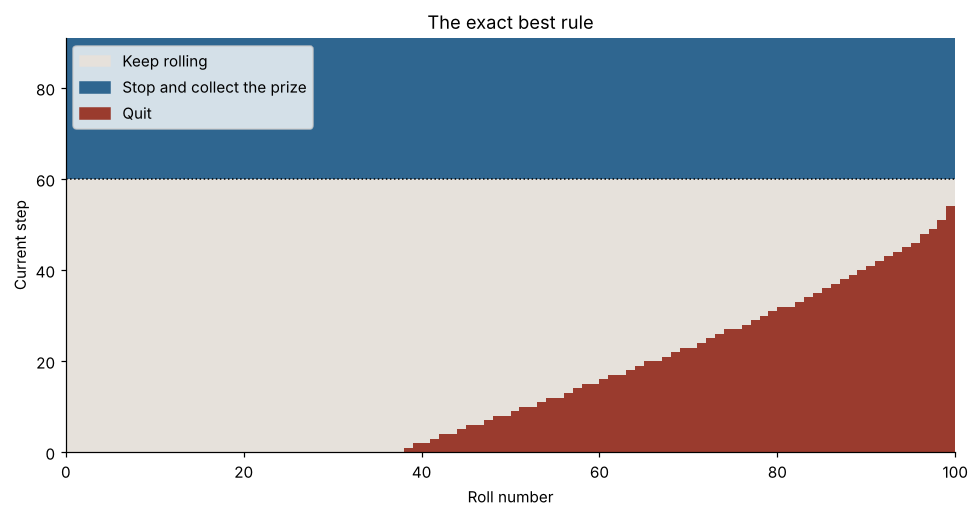

In [4]:
def policy_image(roll_mask, max_step=90):
    # 0 = roll, 1 = collect the prize, 2 = quit
    img = np.zeros((max_step + 1, ROLLS))
    for t in range(ROLLS):
        for s in range(max_step + 1):
            img[s, t] = 0 if roll_mask[t, s] else (1 if s >= TARGET else 2)
    return img

cmap = ListedColormap(["#e6e1db", BLUE, RED])
legend = [Patch(color="#e6e1db", label="Keep rolling"), Patch(color=BLUE, label="Stop and collect the prize"),
          Patch(color=RED, label="Quit")]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.imshow(policy_image(best_roll), origin="lower", aspect="auto", cmap=cmap, vmin=0, vmax=2, extent=[0, ROLLS, 0, 91])
ax.axhline(TARGET, color="black", ls=":", lw=1)
ax.set_xlabel("Roll number"); ax.set_ylabel("Current step"); ax.grid(False)
ax.set_title("The exact best rule"); ax.legend(handles=legend, loc="upper left", frameon=True)
plt.tight_layout(); plt.show()

### How to read it
Find your roll number along the bottom and your step up the side. The colour tells you what to do. Blue above the dotted line is the prize zone. The red wedge in the lower right is the quit zone. Grey in between is the keep-rolling zone.

### What it means
The map matches the three-part rule above. The red wedge starts around roll 40 at the bottom and widens as the game goes on, climbing toward the target line at the very end. Near the last roll almost everything below 60 is red, because with few rolls left only a very lucky roll can still reach the prize and it is not worth the fee.

### What's next and why
This rule needed the exact transition probabilities of every die roll. The next question is the interesting one for machine learning: can a program find the rule without being told the probabilities?

## 5. Q-learning: learning the rule by playing

### What we are looking for
A learner that is **not** told the rules of the dice. It only plays games and sees the results. For every position (roll number, step) it keeps two scores, the **Q-values**: how good it thinks it is to *roll* and how good it thinks it is to *stop*. After each action it nudges the score it just used toward what it actually saw:

> new score = old score + learning rate × (what I just saw − old score)

what it saw = the immediate payoff (the prize on stopping, or minus the fee on rolling) plus the best score of the position it landed on. Two ingredients make this work:

- **Exploration:** 30% of the time at first (falling to 2%) it picks a random action, so that it tries things it does not yet believe in.
- **Optimistic start:** every score starts at 1, the best payoff possible, so every untried action looks promising until it is tried and found wanting.

We train for 400,000 games, and every 20,000 games we freeze the learner's current rule and score it exactly with the same method as section 2. That gives a learning curve.

Training took 29 seconds.

 Games played  Payoff of the learned rule   Gap to the best (0.426)
       40,000                      -0.166                     0.592
       80,000                      -0.198                     0.624
      120,000                      -0.217                     0.643
      160,000                      -0.230                     0.656
      200,000                      -0.091                     0.517
      240,000                       0.206                     0.220
      280,000                       0.415                     0.011
      320,000                       0.413                     0.013
      360,000                       0.412                     0.014
      400,000                       0.412                     0.014


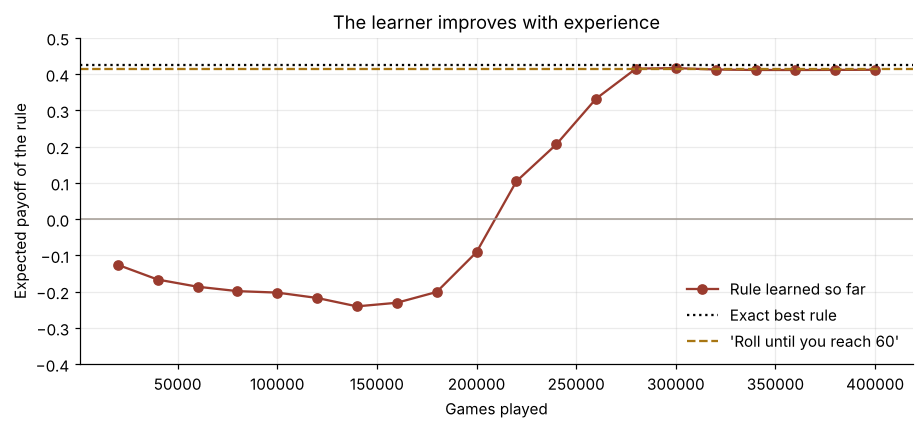

In [5]:
import time
start = time.time()
Q, snapshots = q_learn(episodes=400_000, rolls=ROLLS, target=TARGET, clumsy=CLUMSY, fee=FEE,
                       seed=0, checkpoint_every=20_000)
print(f"Training took {time.time() - start:.0f} seconds.\n")

best_value = W[0, 0]
curve = [(n, evaluate_policy(mask, ROLLS, TARGET, CLUMSY, FEE)) for n, mask in snapshots]
print(f"{'Games played':>13}{'Payoff of the learned rule':>28}{'Gap to the best (0.426)':>26}")
for n, v in curve[1::2]:
    print(f"{n:>13,}{v:>28.3f}{best_value - v:>26.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot([n for n, v in curve], [v for n, v in curve], "o-", color=RED, label="Rule learned so far")
ax.axhline(best_value, color="black", ls=":", label="Exact best rule")
ax.axhline(evaluate_policy(bank_at_target, ROLLS, TARGET, CLUMSY, FEE), color=GOLD, ls="--", label="'Roll until you reach 60'")
ax.axhline(0, color=GREY, lw=1)
ax.set_xlabel("Games played"); ax.set_ylabel("Expected payoff of the rule"); ax.set_ylim(-0.4, 0.5)
ax.set_title("The learner improves with experience"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

### How to read it
Each point is the learner's rule at that moment, scored exactly. The dotted line is the best possible rule, the dashed gold line is the simple "roll until you reach 60" rule and the grey line at 0 is "stop at once".

### What it means
The learner starts out worse than doing nothing (below 0). That is the optimistic start at work: untried positions look great, so it rolls nearly everywhere and pays fees for nothing. It stays there for the first 200,000 games, then jumps between 200,000 and 280,000 games as it has tried enough positions to learn that most are not so great and exploration fades. By 400,000 games its rule pays 0.412, within 0.014 of the best possible 0.426.

Be careful with that result, though. The simple "roll until you reach 60" rule pays 0.414, slightly *more* than the learned rule. So the learner has found the big idea, **collect the prize when you reach the target**, entirely from experience, but it has not (yet) learned to quit profitably. Quitting is worth only 0.012 of a prize per game, and that is hard to pick out of noisy experience.

### What's next and why
A payoff close to optimal is not the same as the same *rule*. We look at where the learned rule differs from the exact one, and whether the differences matter.

## 6. Learned rule against the exact rule

### What we are looking for
The learned rule drawn as the same map as before, and a count of where it disagrees with the exact answer. Not all positions are equal: only a few are ever visited. So we count disagreements two ways, over all positions on the map and **weighted by how often a climber following the best rule actually is there**.

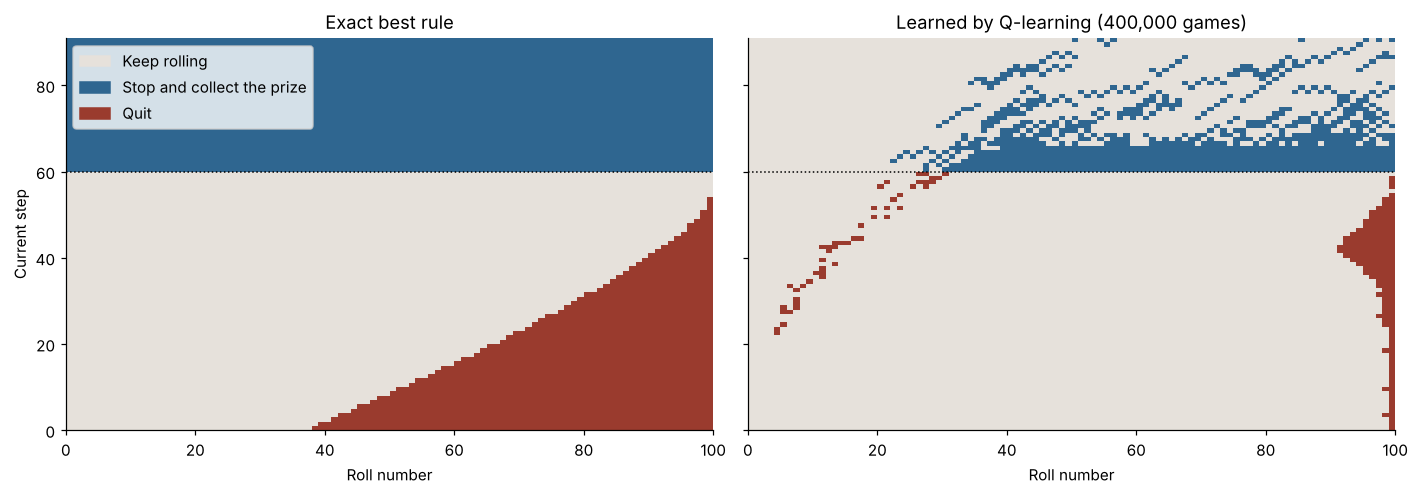

Positions on the map that differ:                 45.5%
Share of real play spent in positions that differ: 0.31%
Payoff of the learned rule: 0.4122   exact best: 0.4259


In [6]:
learned_roll = greedy_roll_mask(Q, ROLLS)[:, :]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, mask, title in [(axes[0], best_roll, "Exact best rule"), (axes[1], learned_roll, "Learned by Q-learning (400,000 games)")]:
    ax.imshow(policy_image(mask), origin="lower", aspect="auto", cmap=cmap, vmin=0, vmax=2, extent=[0, ROLLS, 0, 91])
    ax.axhline(TARGET, color="black", ls=":", lw=1); ax.set_xlabel("Roll number"); ax.set_title(title); ax.grid(False)
axes[0].set_ylabel("Current step"); axes[0].legend(handles=legend, loc="upper left", frameon=True)
plt.tight_layout(); plt.show()

occ = occupancy(best_roll, ROLLS, CLUMSY)                         # how often each position is visited
region = (np.arange(size) <= 100)[None, :] & np.ones((ROLLS, 1), dtype=bool)
differ = (best_roll != learned_roll) & region
weight = occ * region
print(f"Positions on the map that differ:                 {differ.sum() / region.sum():.1%}")
print(f"Share of real play spent in positions that differ: {(occ * differ).sum() / weight.sum():.2%}")
print(f"Payoff of the learned rule: {evaluate_policy(learned_roll, ROLLS, TARGET, CLUMSY, FEE):.4f}   exact best: {best_value:.4f}")

### How to read it
The left map is the exact rule, the right map is what Q-learning found. The first number counts how many of the map's positions have different colours between the two; the second counts the same thing but weighted by how often a climber is actually in each position, which is what decides the payoff.

### What it means
The two maps are not the same, and it is worth being honest about how. The learner has the blue "collect" band right along the bottom edge of the prize zone (steps 60 and just above), where climbers actually arrive. Higher up the picture is ragged, because climbers rarely get that far and those cells were barely tried. The big difference is the red quit wedge: the exact rule has a wide wedge from about roll 40, but the learner found only a few scattered cells of it and a patch right at the end of the game.

The 45.5% of positions that differ sounds large, but a climber following the best rule spends only 0.31% of the time in them. That is why the payoff is still close (0.412 against 0.426). The missing 0.014 is the quit wedge. It is hard to learn because the choice there depends on tiny payoff differences (the fee is only 0.005 per roll), which are easily drowned by the luck of individual games.

**What would help:** many more games, a learning rate that shrinks as a position is visited more, or a model that shares what it learns between neighbouring positions (a neural network for the Q-values, which is how modern deep reinforcement learning works) instead of a separate table entry for each position.

### What's next and why
The fee is the one setting that defines this game. We now vary it, using the exact method, to see how the best rule responds.

## 7. What if the fee changes?

### What we are looking for
How the best rule and its payoff depend on the cost of a roll. We solve the game exactly for four fees. For each we report the best expected payoff and how high a step still gets you to quit after roll 70.

 Fee per roll  Best payoff   Quit at/below step (roll 70)   Quit at/below step (roll 90)
        0.000        0.811                           none                           none
        0.002        0.656                             17                             37
        0.005        0.426                             22                             40
        0.010        0.058                             28                             42
        0.020        0.000                             34                             45


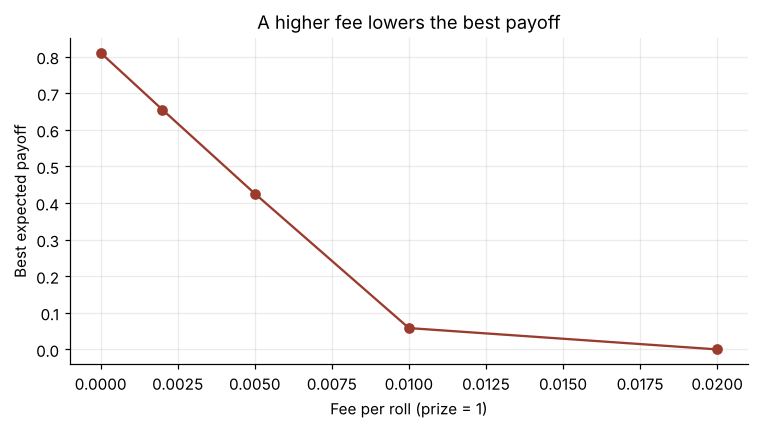

In [7]:
fees = [0.0, 0.002, 0.005, 0.01, 0.02]
print(f"{'Fee per roll':>13}{'Best payoff':>13}{'Quit at/below step (roll 70)':>31}{'Quit at/below step (roll 90)':>31}")
rows = []
for f in fees:
    Wf, contf, stopf = optimal_stopping(ROLLS, TARGET, CLUMSY, f)
    rollf = contf[:ROLLS] > stopf[None, :]
    def boundary(t):
        z = np.where(~rollf[t, :TARGET])[0]
        return int(z.max()) if len(z) else None
    rows.append((f, Wf[0, 0], boundary(70), boundary(90)))
    b70, b90 = boundary(70), boundary(90)
    print(f"{f:>13.3f}{Wf[0, 0]:>13.3f}{('none' if b70 is None else b70):>31}{('none' if b90 is None else b90):>31}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([r[0] for r in rows], [r[1] for r in rows], "o-", color=RED)
ax.set_xlabel("Fee per roll (prize = 1)"); ax.set_ylabel("Best expected payoff")
ax.set_title("A higher fee lowers the best payoff"); plt.tight_layout(); plt.show()

### How to read it
Each row is a different fee. "Best payoff" is the exact best expected payoff. The two right-hand columns say how high a step still gets you to quit at roll 70 and at roll 90; "none" means no step is worth quitting at.

### What it means
With no fee at all the best payoff is 0.811, which is the chance of ever reaching 60 within 100 rolls (a bit higher than the 77.7% chance of *finishing* on 60 or more, because you can stop the moment you get there). As the fee rises the best payoff falls steadily, and the quit line rises: at a fee of 0.02 even a climber on step 34 after 70 rolls should give up, and the best payoff is 0.000, which means the game is not worth starting at all. With no fee there is never a reason to quit, since waiting costs nothing.

The shape of the answer matches common sense and the exact math says exactly how much: **the more it costs to keep going, the earlier you should walk away.**

### What's next and why
We now have the exact rule, a learner that found nearly the same rule on its own and a sense of how the rule moves with the fee. The summary pulls it together, and notebook 06 then goes back to the learner's one weakness (the quit zone) to find out why it happened and fix it.

## 8. Summary

| Question | Result | Method |
|---|---|---|
| Payoff of simple rules | stop at once 0, play all 100 about 0.28, roll until 60 about 0.41 | Exact policy evaluation |
| Best possible payoff | 0.426 | Dynamic programming (backwards) |
| The best rule | collect at 60+, quit when too far behind for the time left, otherwise roll | Dynamic programming |
| What Q-learning achieved after 400,000 games | 0.412: within 0.014 of the best, but no better than 'roll until 60' (0.414) | Tabular Q-learning with optimistic start |
| Where the learned rule differs | the quit wedge (mostly missed; **notebook 06 finds why and fixes it**) and rarely visited high steps | Rule comparison, weighted by visits |
| Effect of a higher fee | lower payoff, quit earlier | Exact solution at several fees |

**Takeaways**
1. A choice turns a game of chance into a decision problem, and the same backwards recursion that made the value map solves it exactly.
2. Q-learning needs no knowledge of the probabilities, only experience. From experience alone it found the main idea (collect the prize at the target), but missed the small extra gain from quitting, which the exact method finds easily. Learning from experience is slower and noisier when the differences between choices are small.
3. Optimism at the start drives exploration, but it makes early performance worse than doing nothing.
4. Because the exact answer exists, we could measure the learner honestly instead of trusting that it "seems to work".
5. **What's next:** the missed quit zone had two causes, and fixing both brings the learner to 0.4251 against the best 0.4259. That is notebook 06.

**Where the code lives:** `src/stopping.py` (functions `optimal_stopping`, `evaluate_policy`, `occupancy`, `q_learn`), covered by `tests/test_stopping.py`.